# CineCue: 5. Matrix factorization, context, and the test comparison

Run notebook 4 first. Matrix factorization (MF) gives every user and movie a vector of
*k* latent factors on top of the bias model:

score(u, i) = mean + b_i + b_u + p_u · q_i

We fit it by alternating least squares (ALS). With movie vectors held fixed, each user
vector is the solution of a small ridge regression, and the reverse holds for movies. The
penalty grows with the number of ratings (Zhou et al., 2008), so all users and movies are
shrunk on the same scale. Because a user vector is a ridge solution, a profile can be
recomputed in an instant from any rating history. That makes the online protocol from
notebook 4 cheap, and notebook 7 relies on it for exact explanations.

Steps:

1. Tune the factor count *k* and the penalty on validation (online RMSE, as in notebook 4).
2. Test whether UTC submission context adds anything beyond MF.
3. Refit the chosen models on train + validation and score the test split once.

In [1]:
from pathlib import Path
import json
import sys
import numpy as np
import pandas as pd
from IPython.display import display, Markdown

# Work from either the repository root or its notebooks directory.
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
assert (ROOT / "requirements.txt").is_file(), "Open this notebook from the cloned repository."
sys.path.insert(0, str(ROOT / "src"))
PROCESSED = ROOT / "data" / "processed"
pd.set_option("display.max_columns", 20)
pd.set_option("display.float_format", "{:.4f}".format)

import time
import matplotlib.pyplot as plt
from cinecue.data import load_splits
from cinecue.evaluation import by_segment, overall, segment_labels
from cinecue.models import (BiasModel, ContextOffsets, GlobalMean, MatrixFactorization, WithContext,
                            online_predict, rmse)

splits = load_splits(PROCESSED)
train, validation, test = (splits[name] for name in ["train", "validation", "test"])
baseline = json.loads((PROCESSED / "baseline_summary.json").read_text(encoding="utf-8"))
bias_params = baseline["selected"]
print("Bias regularization from notebook 4:", bias_params)
print("Validation baseline RMSE:", {name: round(row["RMSE"], 4) for name, row in baseline["validation"].items()})

Bias regularization from notebook 4: {'user_reg': 10.0, 'item_reg': 2.0}
Validation baseline RMSE: {'global mean': 1.1191, 'bias (frozen)': 0.9678, 'bias (online)': 0.9141}


## Tuning factors and regularization

Each configuration runs 10 ALS iterations from a fixed random seed. We record frozen
and online validation RMSE and select by online RMSE.

In [2]:
grid = []
for factors in [16, 32, 64]:
    for reg in [0.05, 0.08, 0.12]:
        start = time.perf_counter()
        model = MatrixFactorization(factors=factors, reg=reg, n_iter=10).fit(train.user_id, train.movie_id, train.rating)
        grid.append({"factors": factors, "reg": reg, "train RMSE": model.history[-1],
                     "frozen RMSE": rmse(validation.rating, model.predict(validation.user_id, validation.movie_id)),
                     "online RMSE": rmse(validation.rating, online_predict(model, train, validation)),
                     "seconds": time.perf_counter() - start})
grid = pd.DataFrame(grid)
best = grid.loc[grid["online RMSE"].idxmin()]
display(grid)
print(f"Selected factors={best.factors:.0f}, reg={best.reg:g}: online RMSE {best['online RMSE']:.4f}")

,factors,reg,train RMSE,frozen RMSE,online RMSE,seconds
0,16,0.0500,0.7326,0.9642,0.8778,8.2292
1,16,0.0800,0.7745,0.9613,0.8727,8.2191
2,16,0.1200,0.8359,0.9628,0.8847,8.6866
3,32,0.0500,0.6710,0.9649,0.8797,12.0671
4,32,0.0800,0.7456,0.9610,0.8714,12.3753
5,32,0.1200,0.8334,0.9629,0.8843,10.9149
6,64,0.0500,0.6025,0.9651,0.8769,43.4701
7,64,0.0800,0.7223,0.9608,0.8694,30.6445
8,64,0.1200,0.8317,0.9628,0.8840,33.8732


Selected factors=64, reg=0.08: online RMSE 0.8694


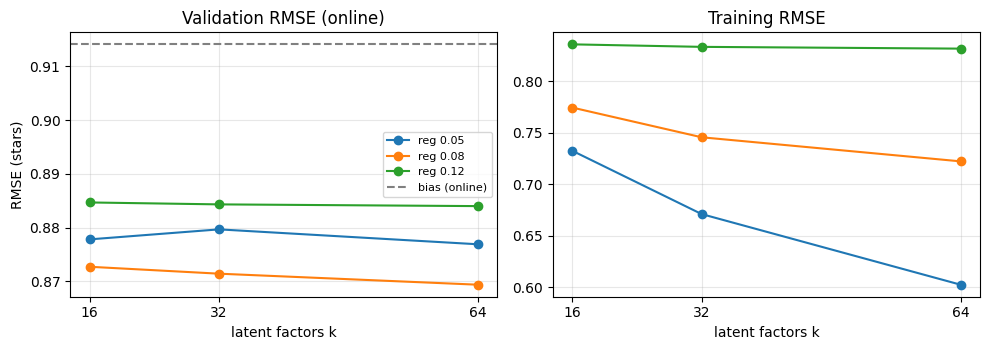

**Interpretation:** At every k, lowering the penalty from 0.08 to 0.05 lowers training RMSE but raises validation RMSE: the weaker penalty overfits. More factors help only a little: going from k=32 to k=64 lowers online validation RMSE by 0.0020, so the gains are flattening out. The selected model reaches 0.8694, against 0.9141 for the online bias model.

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for reg, group in grid.groupby("reg"):
    axes[0].plot(group.factors, group["online RMSE"], marker="o", label=f"reg {reg:g}")
    axes[1].plot(group.factors, group["train RMSE"], marker="o", label=f"reg {reg:g}")
for axis, title in zip(axes, ["Validation RMSE (online)", "Training RMSE"]):
    axis.set(title=title, xlabel="latent factors k", xticks=[16, 32, 64])
    axis.grid(alpha=0.3)
axes[0].axhline(baseline["validation"]["bias (online)"]["RMSE"], color="grey", ls="--", label="bias (online)")
axes[0].set_ylabel("RMSE (stars)")
axes[0].legend(fontsize=8)
fig.tight_layout()
plt.show()
online_by = grid.pivot(index="factors", columns="reg", values="online RMSE")
train_by = grid.pivot(index="factors", columns="reg", values="train RMSE")
low_reg = grid.reg.min()
overfits = bool((train_by[low_reg] < train_by[best.reg]).all() and (online_by[low_reg] > online_by[best.reg]).all())
k_values = sorted(grid.factors.unique())
k_gain = online_by.loc[k_values[-2], best.reg] - online_by.loc[k_values[-1], best.reg]
display(Markdown(
    f"**Interpretation:** " + (f"At every k, lowering the penalty from {best.reg:g} to {low_reg:g} lowers training "
    f"RMSE but raises validation RMSE: the weaker penalty overfits. " if overfits else "")
    + f"More factors help only a little: going from k={k_values[-2]} to k={k_values[-1]} lowers online "
    f"validation RMSE by {k_gain:.4f}, so the gains are flattening out. The selected model reaches {best['online RMSE']:.4f}, "
    f"against {baseline['validation']['bias (online)']['RMSE']:.4f} for the online bias model."))

In [4]:
mf = MatrixFactorization(factors=int(best.factors), reg=float(best.reg), n_iter=10).fit(
    train.user_id, train.movie_id, train.rating)
print("Training RMSE by ALS iteration:", np.round(mf.history, 4))
assert mf.history[-1] <= mf.history[0]

Training RMSE by ALS iteration: [0.835  0.7764 0.752  0.7405 0.734  0.7299 0.7271 0.725  0.7235 0.7223]


## Does UTC context help?

The only context in MovieLens 1M is when a rating was submitted, in UTC. We test two
plausible effects on top of MF:

* a **user × weekend** offset: some users may rate differently on weekends;
* a **movie × six-hour UTC block** offset: some movies may be rated differently by time of day.

Each offset is a shrunken mean of training residuals, sum / (count + reg), so rare
combinations stay near 0. The offsets are fitted on training rows only.
**Decision rule, set before looking at the results:** keep context only if it lowers
online validation RMSE by at least 0.002 stars. A smaller gain does not justify the extra
parameters.

In [5]:
mf_frozen = mf.predict(validation.user_id, validation.movie_id)
mf_online = online_predict(mf, train, validation)
context_rows = []
for reg in [25, 100, 400]:
    offsets = ContextOffsets([("user_id", "is_weekend_utc"), ("movie_id", "daypart_utc")], reg=reg)
    contextual = WithContext(mf, offsets).fit(train)
    shift = offsets.predict(validation)
    context_rows.append({"context reg": reg,
                         "frozen RMSE": rmse(validation.rating, contextual.predict_frame(validation)),
                         "online RMSE": rmse(validation.rating, np.clip(mf_online + shift, 1, 5)),
                         "mean |offset|": float(np.abs(shift).mean())})
context = pd.DataFrame(context_rows)
display(context)
context_gain = rmse(validation.rating, mf_online) - context["online RMSE"].min()
use_context = bool(context_gain >= 0.002)
display(Markdown(
    f"**Interpretation:** The best context setting lowers online validation RMSE by only {context_gain:.4f} stars "
    f"({rmse(validation.rating, mf_online):.4f} → {context['online RMSE'].min():.4f}). "
    + ("This passes the 0.002 threshold, so context is kept." if use_context else
       "This is below the 0.002 threshold, so the final models do not use UTC context. Submission "
       "time in UTC says little about a user's local situation; the README already treats it as a weak signal.")))

,context reg,frozen RMSE,online RMSE,mean |offset|
0,25,0.9602,0.8697,0.0437
1,100,0.9599,0.8691,0.0285
2,400,0.9601,0.8690,0.0137


**Interpretation:** The best context setting lowers online validation RMSE by only 0.0003 stars (0.8694 → 0.8690). This is below the 0.002 threshold, so the final models do not use UTC context. Submission time in UTC says little about a user's local situation; the README already treats it as a weak signal.

## Validation comparison

In [6]:
bias = BiasModel(**bias_params).fit(train.user_id, train.movie_id, train.rating)
global_mean = GlobalMean().fit(train.user_id, train.movie_id, train.rating)
validation_predictions = {
    "global mean": global_mean.predict(validation.user_id, validation.movie_id),
    "bias (frozen)": bias.predict(validation.user_id, validation.movie_id),
    "bias (online)": online_predict(bias, train, validation),
    "MF (frozen)": mf_frozen, "MF (online)": mf_online}
validation_results = overall(validation.rating, validation_predictions)
display(validation_results)
labels = segment_labels(validation, train)
display(by_segment(validation.rating, validation_predictions, labels["user history"])
        .rename_axis("training ratings per user"))

,RMSE,MAE
global mean,1.1191,0.9366
bias (frozen),0.9678,0.7694
bias (online),0.9141,0.7211
MF (frozen),0.9608,0.7711
MF (online),0.8694,0.6847


,rows,global mean,bias (frozen),bias (online),MF (frozen),MF (online)
training ratings per user,,,,,,
0 (new),76176,1.1219,0.9855,0.9217,0.9914,0.8821
1-19,2725,1.0426,0.9240,0.8935,0.9109,0.8618
20-99,5390,1.0571,0.9007,0.8805,0.8743,0.8440
100-299,7644,1.0581,0.8680,0.8620,0.8222,0.8024
300+,8085,1.2099,0.9464,0.9186,0.8554,0.8283


## Final test comparison

The settings are now fixed. As in deployment, every model is refitted on train +
validation, and the test split is scored once. For the online protocol, a test rating
may use train + validation plus the same user's earlier test ratings.

In [7]:
history = pd.concat([train, validation], ignore_index=True)
final_models = {
    "global mean": GlobalMean().fit(history.user_id, history.movie_id, history.rating),
    "bias": BiasModel(**bias_params).fit(history.user_id, history.movie_id, history.rating),
    "MF": MatrixFactorization(factors=int(best.factors), reg=float(best.reg), n_iter=10).fit(
        history.user_id, history.movie_id, history.rating)}
test_predictions = {"global mean": final_models["global mean"].predict(test.user_id, test.movie_id)}
for name in ["bias", "MF"]:
    test_predictions[f"{name} (frozen)"] = final_models[name].predict(test.user_id, test.movie_id)
    test_predictions[f"{name} (online)"] = online_predict(final_models[name], history, test)
if use_context:
    offsets = ContextOffsets([("user_id", "is_weekend_utc"), ("movie_id", "daypart_utc")],
                             reg=int(context.loc[context["online RMSE"].idxmin(), "context reg"]))
    WithContext(final_models["MF"], offsets).fit(history)
    test_predictions["MF + context (online)"] = np.clip(test_predictions["MF (online)"] + offsets.predict(test), 1, 5)
test_results = overall(test.rating, test_predictions)
test_labels = segment_labels(test, history)
test_by_user = by_segment(test.rating, test_predictions, test_labels["user history"])
test_by_movie = by_segment(test.rating, test_predictions, test_labels["movie history"])
display(test_results)
display(test_by_user.rename_axis("train + validation ratings per user"))
display(test_by_movie.rename_axis("train + validation ratings per movie"))

,RMSE,MAE
global mean,1.0893,0.9025
bias (frozen),0.9198,0.7205
bias (online),0.8937,0.7007
MF (frozen),0.8933,0.6997
MF (online),0.8508,0.6670


,rows,global mean,bias (frozen),bias (online),MF (frozen),MF (online)
train + validation ratings per user,,,,,,
0 (new),4209,1.0999,0.9834,0.9374,0.9815,0.8811
1-19,10022,1.1093,0.9523,0.9118,0.9776,0.8777
20-99,22238,1.0579,0.9076,0.8777,0.8880,0.8392
100-299,32666,1.0909,0.9254,0.8950,0.8874,0.8497
300+,30886,1.1017,0.9027,0.8917,0.8614,0.8471


,rows,global mean,bias (frozen),bias (online),MF (frozen),MF (online)
train + validation ratings per movie,,,,,,
0 (new),90,0.9794,0.9861,0.9858,1.0008,0.9877
1-19,1390,1.1300,0.9912,0.9715,0.9939,0.9629
20-99,8634,1.2067,0.9483,0.9252,0.9373,0.8964
100-499,41995,1.1286,0.9176,0.8910,0.8953,0.8519
500+,47912,1.0293,0.9142,0.8878,0.8799,0.8374


In [8]:
mf_test, bias_test = test_results.loc["MF (online)", "RMSE"], test_results.loc["bias (online)", "RMSE"]
mean_test = test_results.loc["global mean", "RMSE"]
online_gain = test_by_user["MF (frozen)"] - test_by_user["MF (online)"]
seen_share = (test_labels["user history"] != "0 (new)").mean()
validation_gap = validation_results.loc["MF (frozen)", "RMSE"] - validation_results.loc["MF (online)", "RMSE"]
display(Markdown(
    f"**Interpretation:** On the test split, online MF reaches RMSE {mf_test:.3f}, against {bias_test:.3f} for "
    f"online biases and {mean_test:.3f} for the global mean ({1 - mf_test / mean_test:.1%} lower). "
    + ("Online updates lower MF error in every user-history group. " if (online_gain > 0).all() else "")
    + f"The gain is largest for the '{online_gain.idxmax()}' group ({online_gain.max():.3f} stars) and smallest for "
    f"'{online_gain.idxmin()}' ({online_gain.min():.3f}). {seen_share:.1%} of test ratings come from users seen "
    f"before the test period, so the overall frozen-to-online gap ({test_results.loc['MF (frozen)', 'RMSE'] - mf_test:.3f}) "
    f"is smaller than on validation ({validation_gap:.3f}), where most users were new."))

**Interpretation:** On the test split, online MF reaches RMSE 0.851, against 0.894 for online biases and 1.089 for the global mean (21.9% lower). Online updates lower MF error in every user-history group. The gain is largest for the '0 (new)' group (0.100 stars) and smallest for '300+' (0.014). 95.8% of test ratings come from users seen before the test period, so the overall frozen-to-online gap (0.043) is smaller than on validation (0.091), where most users were new.

In [9]:
summary = {
    "bias": bias_params,
    "mf": {"factors": int(best.factors), "reg": float(best.reg), "n_iter": 10, "seed": 0},
    "context": {"kept": use_context, "validation_online_gain": float(context_gain),
                "grid": context.to_dict(orient="records")},
    "mf_grid": grid.drop(columns="seconds").to_dict(orient="records"),
    "validation": validation_results.to_dict(orient="index"),
    "test": test_results.to_dict(orient="index"),
    "test_by_user_history": test_by_user.reset_index(names="segment").to_dict(orient="records"),
    "test_by_movie_history": test_by_movie.reset_index(names="segment").to_dict(orient="records")}
(PROCESSED / "rating_summary.json").write_text(json.dumps(summary, indent=2) + "\n", encoding="utf-8")
print("Saved rating_summary.json to data/processed/.")

Saved rating_summary.json to data/processed/.


RMSE measures how well we predict stars on movies that users chose to rate. It says
little about what to show at the top of a list. Notebook 6 evaluates top-10
recommendation lists, popularity bias, and catalog coverage.